In [29]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

raw = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")
print(raw.shape)
print(raw.columns.tolist())
raw.head()

(23486, 11)
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happened to find ...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted i...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and ...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustab...,5,1,6,General,Tops,Blouses


In [30]:
df = raw[["Review Text", "Rating"]].dropna().copy()
df.columns = ["text", "rating"]

def to_label(r):
    if r <= 2:
        return "negative"
    if r == 3:
        return "neutral"
    return "positive"

df["label"] = df["rating"].apply(to_label)

print(df.shape)
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

(22641, 3)
label
positive    17448
neutral      2823
negative     2370
Name: count, dtype: int64
label
positive    0.771
neutral     0.125
negative    0.105
Name: proportion, dtype: float64


In [31]:
t = df["text"]

checks = {
    "contains URL":          t.str.contains(r"http\S+|www\.\S+", case=False, regex=True),
    "contains emoji":        t.str.contains(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", regex=True),
    "repeated letters":      t.str.contains(r"([a-z])\1{2,}", case=False, regex=True),
    "ALL-CAPS word":         t.str.contains(r"\b[A-Z]{3,}\b", regex=True),
    "contains digits":       t.str.contains(r"\d", regex=True),
}
for name, mask in checks.items():
    print(f"{name:20s} {mask.sum():>6,}  ({mask.mean() * 100:.1f}%)")

df["n_words"] = t.str.split().str.len()
print(df["n_words"].describe().round(1))

for _, row in df.sample(5, random_state=1).iterrows():
    print(f"\n[{row['rating']} stars] {row['text'][:200]}")

/tmp/ipykernel_408/2972144839.py:6: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "repeated letters":      t.str.contains(r"([a-z])\1{2,}", case=False, regex=True),


contains URL              0  (0.0%)
contains emoji            0  (0.0%)
repeated letters        300  (1.3%)
ALL-CAPS word             0  (0.0%)
contains digits       8,790  (38.8%)
count    22641.0
mean        60.2
std         28.5
min          2.0
25%         36.0
50%         59.0
75%         88.0
max        115.0
Name: n_words, dtype: float64

[5 stars] I'm taking this to hawaii for the holidays, i'm wearing it with black calf length tights and a black belt. it is fine without tights, i just like that look. it is a really great dress.

[4 stars] I purchased this sweater in the blue and i love the color. at first i bought the regular size extra small. i am 5/2" and 102 pounds. i had to return the xs for the xxs petite. i like the arms to be lo

[5 stars] Absolutely in love with this top. the embroidery and back button detail make for a unique and fun look. light and airy material will be perfect in warmer weather with a cute pair of shorts. i got a si

[4 stars] In the midst of the en

In [32]:
def clean_text(s):
    s = s.lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)                      # links
    s = re.sub(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]", " ", s)  # emojis
    s = s.replace("’", "'")                                      # curly apostrophe
    s = re.sub(r"won't", "will not", s)
    s = re.sub(r"can't", "can not", s)
    s = re.sub(r"n't\b", " not", s)                              # didn't -> did not
    s = re.sub(r"([a-z])\1{2,}", r"\1\1", s)                     # soooo -> soo
    s = re.sub(r"[^a-z\s]", " ", s)                              # punctuation, digits
    s = re.sub(r"\s+", " ", s).strip()
    return s

for example in ["I DON'T like it, sooo bad!!!", "Not good at all", "Loooove it 😍 http://x.com"]:
    print(example, "->", clean_text(example))

df["clean"] = df["text"].apply(clean_text)
df[["text", "clean"]].head(3)

I DON'T like it, sooo bad!!! -> i do not like it soo bad
Not good at all -> not good at all
Loooove it 😍 http://x.com -> loove it


,text,clean
0,Absolutely wonderful - silky and sexy and comfortable,absolutely wonderful silky and sexy and comfortable
1,Love this dress! it's sooo pretty. i happened to find ...,love this dress it s soo pretty i happened to find it in...
2,I had such high hopes for this dress and really wanted i...,i had such high hopes for this dress and really wanted i...


In [33]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=42
)
print(len(X_train), len(X_test))
print(y_train.value_counts(normalize=True).round(3))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def tfidf(stop="english", ngram=(1, 1)):
    return TfidfVectorizer(stop_words=stop, ngram_range=ngram, min_df=2)

def cv_scores(name, model):
    cv = cross_validate(model, X_train, y_train, cv=skf, scoring=["accuracy", "f1_macro"])
    print(f"{name:34s} accuracy {cv['test_accuracy'].mean():.3f} | macro-F1 {cv['test_f1_macro'].mean():.3f}")

cv_scores("Always the most common class",
          Pipeline([("tfidf", tfidf()), ("model", DummyClassifier(strategy="most_frequent"))]))
cv_scores("Naive Bayes (baseline)",
          Pipeline([("tfidf", tfidf()), ("model", MultinomialNB())]))

18112 4529
label
positive    0.771
neutral     0.125
negative    0.105
Name: proportion, dtype: float64
Always the most common class       accuracy 0.771 | macro-F1 0.290
Naive Bayes (baseline)             accuracy 0.776 | macro-F1 0.327


In [34]:
from sklearn.linear_model import LogisticRegression

cv_scores("Naive Bayes, fit_prior=False",
          Pipeline([("tfidf", tfidf()), ("model", MultinomialNB(fit_prior=False))]))
cv_scores("Logistic regression",
          Pipeline([("tfidf", tfidf()), ("model", LogisticRegression(max_iter=1000))]))
cv_scores("Logistic (class_weight)",
          Pipeline([("tfidf", tfidf()), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]))

Naive Bayes, fit_prior=False       accuracy 0.800 | macro-F1 0.558
Logistic regression                accuracy 0.816 | macro-F1 0.554
Logistic (class_weight)            accuracy 0.764 | macro-F1 0.593


In [35]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.base import clone

negations = {"not", "no", "nor", "never", "nothing", "nobody", "none", "cannot", "neither"}
print("Negation words in sklearn's stop list:", sorted(negations & ENGLISH_STOP_WORDS))
stop_keep_neg = sorted(ENGLISH_STOP_WORDS - negations)

setups = {
    "A: sklearn stop words, unigrams":      tfidf("english", (1, 1)),
    "B: keep negations, unigrams":          tfidf(stop_keep_neg, (1, 1)),
    "C: keep negations, unigrams+bigrams":  tfidf(stop_keep_neg, (1, 2)),
    "D: no stop words, unigrams+bigrams":   tfidf(None, (1, 2)),
}

for sname, vec in setups.items():
    cv_scores(f"{sname} | NB",
              Pipeline([("tfidf", vec), ("model", MultinomialNB(fit_prior=False))]))
    cv_scores(f"{sname} | LogReg",
              Pipeline([("tfidf", vec), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]))

Negation words in sklearn's stop list: ['cannot', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing']
A: sklearn stop words, unigrams | NB accuracy 0.800 | macro-F1 0.558
A: sklearn stop words, unigrams | LogReg accuracy 0.764 | macro-F1 0.593
B: keep negations, unigrams | NB   accuracy 0.800 | macro-F1 0.559
B: keep negations, unigrams | LogReg accuracy 0.767 | macro-F1 0.596
C: keep negations, unigrams+bigrams | NB accuracy 0.780 | macro-F1 0.349
C: keep negations, unigrams+bigrams | LogReg accuracy 0.794 | macro-F1 0.613
D: no stop words, unigrams+bigrams | NB accuracy 0.773 | macro-F1 0.303
D: no stop words, unigrams+bigrams | LogReg accuracy 0.806 | macro-F1 0.635


In [36]:
tricky = [
    ("The fabric is not good and it fits badly", "negative"),
    ("Not good at all, very disappointed", "negative"),
    ("I would never buy this again", "negative"),
    ("It does not fit and the color is not as pictured", "negative"),
    ("Not comfortable, not flattering, returning it", "negative"),
    ("This is not bad at all, I really like it", "positive"),
    ("No complaints, it fits perfectly", "positive"),
    ("I could not be happier with this dress", "positive"),
    ("I have never loved a sweater more", "positive"),
    ("It is okay, nothing special", "neutral"),
    ("Fits fine but the color is a bit different than the photo", "neutral"),
    ("Decent for the price, not amazing", "neutral"),
    ("Great, it fell apart after one wash", "negative"),
    ("Oh wonderful, another dress that does not fit", "negative"),
]
tricky_df = pd.DataFrame(tricky, columns=["text", "expected"])
tricky_df["clean"] = tricky_df["text"].apply(clean_text)

for key in ["A", "B", "C"]:
    vec = [v for k, v in setups.items() if k.startswith(key)][0]
    m = Pipeline([("tfidf", clone(vec)),
                  ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    m.fit(X_train, y_train)
    tricky_df[key] = m.predict(tricky_df["clean"])

pd.set_option("display.max_colwidth", 60)
print(tricky_df[["text", "expected", "A", "B", "C"]].to_string())
for key in ["A", "B", "C"]:
    print(key, "correct:", (tricky_df[key] == tricky_df["expected"]).sum(), "of", len(tricky_df))

                                                         text  expected         A         B         C
0                    The fabric is not good and it fits badly  negative  negative  negative  negative
1                          Not good at all, very disappointed  negative  negative  negative  negative
2                                I would never buy this again  negative  positive  positive  positive
3            It does not fit and the color is not as pictured  negative   neutral   neutral   neutral
4               Not comfortable, not flattering, returning it  negative   neutral  negative  negative
5                    This is not bad at all, I really like it  positive  negative  negative   neutral
6                            No complaints, it fits perfectly  positive  positive  positive  positive
7                      I could not be happier with this dress  positive  negative  negative  positive
8                           I have never loved a sweater more  positive  negative 

Setup D + LogReg
Accuracy: 0.806 | macro-F1: 0.638
              precision    recall  f1-score   support

    negative       0.52      0.59      0.56       474
     neutral       0.38      0.52      0.44       565
    positive       0.95      0.88      0.92      3490

    accuracy                           0.81      4529
   macro avg       0.62      0.66      0.64      4529
weighted avg       0.84      0.81      0.82      4529



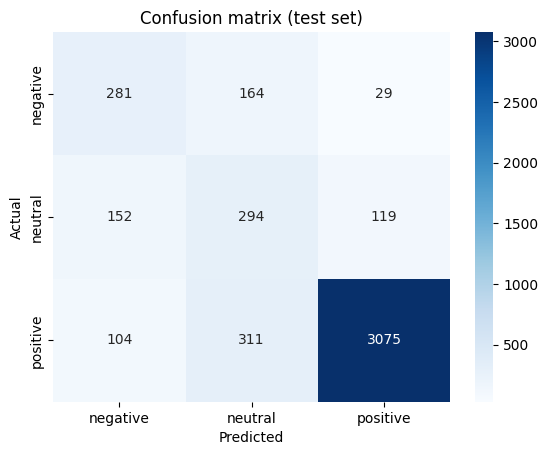

In [37]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

best_setup = "D"        # change to the best setup letter in your Step 7 table
best_model = "LogReg"   # "LogReg" or "NB"

vec = [v for k, v in setups.items() if k.startswith(best_setup)][0]
mdl = (LogisticRegression(max_iter=1000, class_weight="balanced")
       if best_model == "LogReg" else MultinomialNB(fit_prior=False))
final = Pipeline([("tfidf", clone(vec)), ("model", mdl)]).fit(X_train, y_train)

labels = ["negative", "neutral", "positive"]
pred = final.predict(X_test)

print(f"Setup {best_setup} + {best_model}")
print("Accuracy:", round(accuracy_score(y_test, pred), 3),
      "| macro-F1:", round(f1_score(y_test, pred, average="macro"), 3))
print(classification_report(y_test, pred, labels=labels))

cm = confusion_matrix(y_test, pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (test set)")
plt.show()

In [38]:
test_df = pd.DataFrame({
    "text": df.loc[X_test.index, "text"],
    "clean": X_test,
    "actual": y_test,
    "pred": pred,
    "conf": final.predict_proba(X_test).max(axis=1),
})
test_df["error"] = test_df["actual"] != test_df["pred"]

errors = test_df[test_df["error"]]
print("Errors:", len(errors), "of", len(test_df))
print(pd.crosstab(errors["actual"], errors["pred"]))

print("\n--- Most confident mistakes ---")
for _, r in errors.sort_values("conf", ascending=False).head(8).iterrows():
    print(f"[actual {r['actual']} | predicted {r['pred']} | confidence {r['conf']:.2f}]")
    print(r["text"][:220], "\n")

Errors: 879 of 4529
pred      negative  neutral  positive
actual                               
negative         0      164        29
neutral        152        0       119
positive       104      311         0

--- Most confident mistakes ---
[actual neutral | predicted positive | confidence 0.99]
Great item and very feminine. can be dressed up or down and fits true to size. 

[actual neutral | predicted positive | confidence 0.94]
This lift weight cardigan is true to size, perfect for fall or spring. colors are quite nice, especially the little pops of orange. 

[actual neutral | predicted positive | confidence 0.92]
I bought this in navy and love the multi textures and look. i'm happy it was on sale because it is so cute but i would not have paid full price on it. it runs small. i plan on wearing it for casual errand days. 

[actual neutral | predicted positive | confidence 0.90]
I bought this in black. it's a great long length. i have long arms so the sleeve length is great. it's re

In [39]:
test_df["has_neg"] = test_df["clean"].str.contains(r"\b(?:not|no|never|nothing)\b")
print(test_df.groupby("has_neg")["error"].agg(["mean", "sum", "count"]).round(3))

          mean  sum  count
has_neg                   
False    0.125  246   1962
True     0.247  633   2567


In [40]:
vec_f = final.named_steps["tfidf"]
mdl_f = final.named_steps["model"]
feat = np.array(vec_f.get_feature_names_out())

if hasattr(mdl_f, "coef_"):
    weights = mdl_f.coef_
else:
    weights = mdl_f.feature_log_prob_ - mdl_f.feature_log_prob_.mean(axis=0)

for i, cls in enumerate(mdl_f.classes_):
    top = np.argsort(weights[i])[::-1][:12]
    print(f"{cls:9s}:", ", ".join(feat[top]))

negative : disappointed, cheap, unflattering, awful, not, looked, was, poor, back, going back, huge, even
neutral  : however, however the, is cute, color and, but, returning it, it just, if, unfortunately, like the, much, not flattering
positive : love, perfect, great, comfortable, little, not too, fits, with, perfectly, soft, love this, compliments


In [41]:
for _, r in errors.sample(20, random_state=3).iterrows():
    print(f"[actual {r['actual']} | predicted {r['pred']}] {r['text'][:250]}\n")

[actual neutral | predicted negative] For fuller busted folks, this top may not work as it's unstructured and results in a tent from the boobs down. it's a shame--i found the gold embellishment beautiful.

[actual positive | predicted neutral] I was so disappointed in this top. the fabric blend was too thick for summer. the cut was wide across the shoulders, and very narrow and short through the waist. add in the odd splashes in the print, and it spelled disaster.

size: i tend to run be

[actual neutral | predicted positive] Cute shirt but it is very hard to wrap my head around being an xxs. sizing is ridiculous. and now that i have an xs that is too big, the xxs are sold out. typical.

[actual positive | predicted neutral] This sweater is a pretty color and style and is really soft and comfortable - i really wanted it to work. a small fit my 5'7", 140 lb frame well (32dd) but the ruffles on the hips were not a wanted addition unfortunately. . tried it on three separate

[actual neutr